# ⚖️ Lesson 5: Model Generalization
**Week 6 · Notebook 5 of 10 · ⏱️ about 120 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Define generalization** and explain why it, not training accuracy, is the real goal.
2. **Diagnose underfitting and overfitting** from training and validation errors, and from curves.
3. **Explain the bias–variance tradeoff** and see it empirically.
4. **Apply regularization** (Ridge and Lasso) and explain *how* a penalty tames a flexible model.
5. **Use cross-validation** to estimate performance reliably and to choose hyperparameters.

## 🗺️ Roadmap
`Generalization` → `Underfitting vs overfitting` → `Bias–variance` → `Regularization` → `Cross-validation` → **Problems**

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV, learning_curve
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.metrics import mean_squared_error

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def poly_model(degree, alpha=None):
    """Polynomial regression pipeline: x -> [x, x², ..., x^degree] -> scale -> (Ridge | plain) regression."""
    reg = LinearRegression() if alpha is None else Ridge(alpha=alpha)
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), reg)

---
# 📖 Part 1: What is generalization?

> **Generalization** = performing well on **new, unseen** data: not just the data you trained on.

Two students prepare for an exam with 20 past-paper questions.

* **Mia memorises the 20 answers word for word.** She aces the past papers (100%). On the real exam (new questions) she flounders.
* **Sam understands the underlying ideas.** He gets ~85% on past papers *and* ~85% on the real exam.

Mia has **low training error but high test error**. She *overfit*. Sam *generalized*. **A model is useful only if it behaves like Sam.**

Let's watch it happen with a model. The data: a smooth curve, `y = sin(2πx)`, observed with noise. We'll give the model only **20 training points** and test it on 60 others.

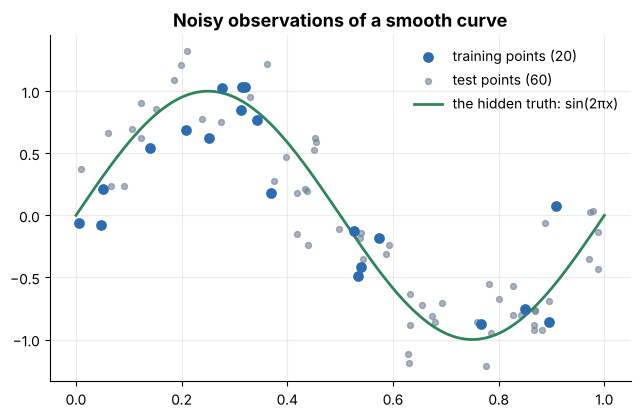

In [2]:
curve = load("noisy_curve.csv")
X_c, y_c = curve[["x"]], curve["y"]
X_tr, X_te, y_tr, y_te = train_test_split(X_c, y_c, train_size=20, random_state=3)

xs = np.linspace(0, 1, 300)
plt.scatter(X_tr["x"], y_tr, color=BLUE, s=45, zorder=3, label="training points (20)")
plt.scatter(X_te["x"], y_te, color=GREY, s=18, alpha=0.6, label="test points (60)")
plt.plot(xs, np.sin(2 * np.pi * xs), color=GREEN, lw=2, label="the hidden truth: sin(2πx)")
plt.legend(); plt.title("Noisy observations of a smooth curve"); plt.show()

---
# 📖 Part 2: Underfitting and overfitting

We'll fit **polynomial regression** models of increasing flexibility. A degree-*d* polynomial is `ŷ = b + w₁x + w₂x² + … + w_d xᵈ`. Higher degree ⇒ more wiggles ⇒ more **model capacity**.

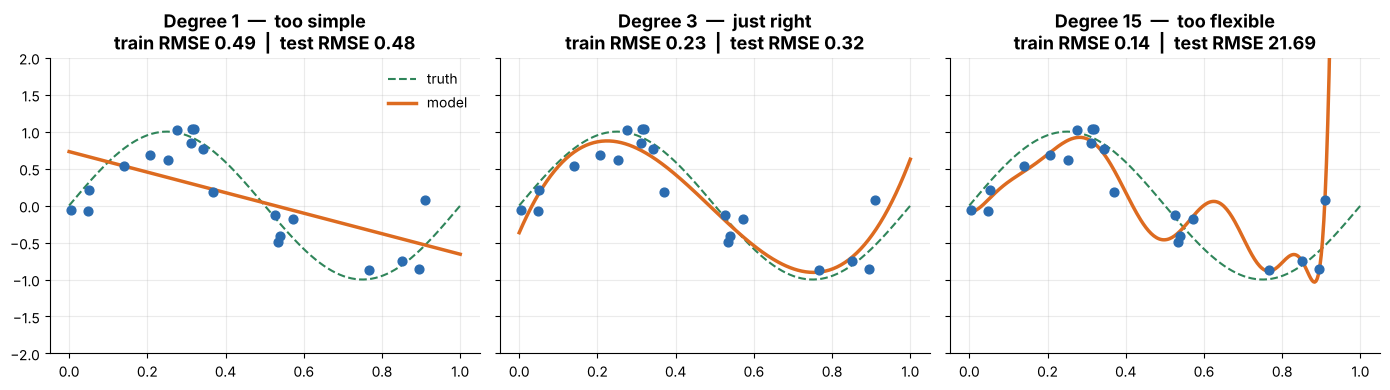

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, deg, title in [(axes[0], 1, "Degree 1: too simple"), (axes[1], 3, "Degree 3: just right"), (axes[2], 15, "Degree 15: too flexible")]:
    m = poly_model(deg).fit(X_tr, y_tr)
    ax.scatter(X_tr["x"], y_tr, color=BLUE, s=40, zorder=3)
    ax.plot(xs, np.sin(2 * np.pi * xs), color=GREEN, lw=1.5, ls="--", label="truth")
    ax.plot(xs, m.predict(pd.DataFrame({"x": xs})), color=ORANGE, lw=2.5, label="model")
    ax.set_ylim(-2, 2)
    ax.set_title(f"{title}\ntrain RMSE {rmse(y_tr, m.predict(X_tr)):.2f}  |  test RMSE {rmse(y_te, m.predict(X_te)):.2f}")
axes[0].legend(); plt.tight_layout(); plt.show()

| | **Underfitting** (degree 1) | **Good fit** (degree 3) | **Overfitting** (degree 15) |
|---|---|---|---|
| Model is… | too simple to capture the pattern | right-sized | so flexible it chases the noise |
| **Training error** | high | low | **very low** |
| **Test error** | high | low (≈ train) | **high** (≫ train) |
| Gap (test − train) | small | small | **large** |
| Also called | **high bias** | - | **high variance** |
| Cure | more flexible model, better features | - | more data, simpler model, **regularization** |

**Diagnostic recipe:**

1. Is the **training error** itself too high? → **underfitting.** More capacity needed.
2. Is training error low but **validation error much higher**? → **overfitting.** Reduce capacity or add data/regularization.
3. Both low and close together? → you're in good shape. 🎉

### 🧑‍🏫 Worked Example 1: Diagnosing from numbers alone

Suppose our goal is an error of about **0.30** (the noise level in the data). Three models report:

| Model | Train RMSE | Validation RMSE | My reasoning | Diagnosis |
|---|---|---|---|---|
| A | 0.48 | 0.50 | train error already above the 0.30 target; the gap is tiny. The model can't even fit its own training data. | **Underfit** |
| B | 0.15 | 0.90 | train error is excellent, but validation is 6× worse. It memorised. | **Overfit** |
| C | 0.27 | 0.31 | both near the target, small gap. | **Good fit** |

*(Notice that A's validation error of 0.50 is "better" than B's 0.90, so judging by validation error alone, A looks better than B! But their cures are opposite: A needs **more** flexibility, B needs **less**. Always look at train **and** validation.)*

## The validation curve: model complexity vs. error

Let's sweep degrees 1 to 12 and plot training vs. test error. The famous U-shape appears:

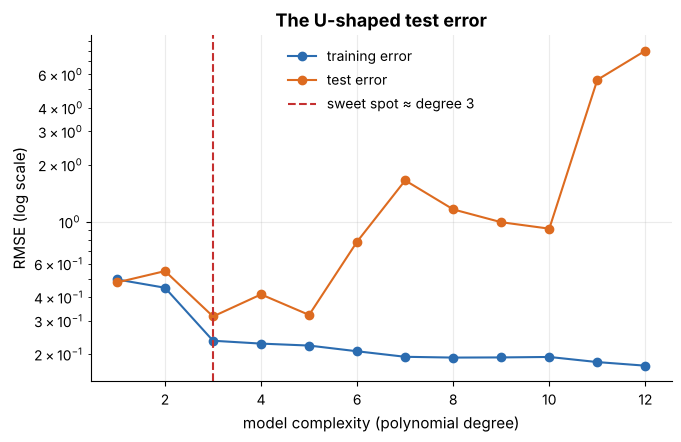

In [4]:
degrees = range(1, 13)
tr_err, te_err = [], []
for d in degrees:
    m = poly_model(d).fit(X_tr, y_tr)
    tr_err.append(rmse(y_tr, m.predict(X_tr)))
    te_err.append(rmse(y_te, m.predict(X_te)))

plt.plot(degrees, tr_err, "o-", color=BLUE, label="training error")
plt.plot(degrees, te_err, "o-", color=ORANGE, label="test error")
plt.yscale("log"); plt.xlabel("model complexity (polynomial degree)"); plt.ylabel("RMSE (log scale)")
best_d = list(degrees)[int(np.argmin(te_err))]
plt.axvline(best_d, color=RED, ls="--", label=f"sweet spot ≈ degree {best_d}")
plt.title("The U-shaped test error"); plt.legend(); plt.show()

* **Training error only ever goes down** as complexity grows: a more flexible model can always fit the training data at least as well.
* **Test error goes down, then up.** Left of the dip → *underfitting*. Right of the dip → *overfitting*. The sweet spot is where **test (or validation) error is lowest**.

---
# 📖 Part 3: The bias–variance tradeoff

*Why* does the U-shape happen? Statisticians decompose a model's expected squared error on new data into three parts:

$$\underbrace{E[(y-\hat y)^2]}_{\text{expected test error}} \;=\; \underbrace{\text{Bias}^2}_{\text{systematic error}} \;+\; \underbrace{\text{Variance}}_{\text{sensitivity to the training sample}} \;+\; \underbrace{\sigma^2}_{\text{irreducible noise}}$$

* **Bias**: *"on average, how far off is the model?"* A straight line fit to a sine wave is wrong **even with infinite data**. That's bias: the model's assumptions are too rigid.
* **Variance**: *"if I retrained on a different random sample, how much would the predictions change?"* A flexible model reshapes itself around every training sample's quirks.
* **Noise σ²**: randomness in the world itself. **No model can remove it.**

> 🎯 **Dartboard analogy.** *High bias:* all darts cluster tightly together but far from the bullseye. *High variance:* darts land all over the board, centred on the bullseye on average. We want darts that are **close to the bullseye *and* tightly grouped.**

Bias falls and variance rises with complexity: that's **the tradeoff**. Let's *measure* it. We repeatedly draw **200 brand-new training sets** of 20 points from the same process, fit a model to each, and study how the predictions behave:

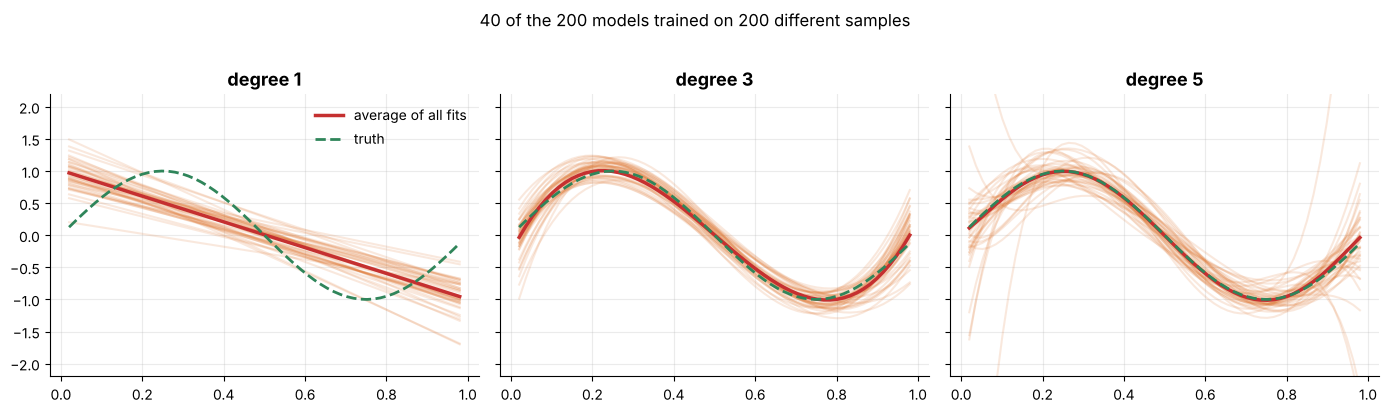

In [5]:
rng = np.random.default_rng(0)
f = lambda x: np.sin(2 * np.pi * x)
noise_sd = 0.3
x_grid = np.linspace(0.02, 0.98, 60)
grid_df = pd.DataFrame({"x": x_grid})

n_sets = 200
results = {}
for deg in [1, 3, 5]:
    preds = np.empty((n_sets, len(x_grid)))
    for s in range(n_sets):
        xt = rng.uniform(0, 1, 20)
        yt = f(xt) + rng.normal(0, noise_sd, 20)
        preds[s] = poly_model(deg).fit(pd.DataFrame({"x": xt}), yt).predict(grid_df)
    results[deg] = preds

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (deg, preds) in zip(axes, results.items()):
    for p in preds[:40]:
        ax.plot(x_grid, p, color=ORANGE, alpha=0.15)
    ax.plot(x_grid, preds.mean(axis=0), color=RED, lw=2.5, label="average of all fits")
    ax.plot(x_grid, f(x_grid), color=GREEN, lw=2, ls="--", label="truth")
    ax.set_ylim(-2.2, 2.2); ax.set_title(f"degree {deg}")
axes[0].legend(); plt.suptitle("40 of the 200 models trained on 200 different samples", y=1.02); plt.tight_layout(); plt.show()

In [6]:
rows = []
for deg, preds in results.items():
    bias2 = np.mean((preds.mean(axis=0) - f(x_grid)) ** 2)      # how far is the AVERAGE model from the truth?
    variance = np.mean(preds.var(axis=0))                        # how much do the models disagree with each other?
    rows.append({"degree": deg, "bias²": bias2, "variance": variance, "noise σ²": noise_sd ** 2,
                 "bias²+var+noise": bias2 + variance + noise_sd ** 2})
pd.DataFrame(rows).set_index("degree").round(3)

,bias²,variance,noise σ²,bias²+var+noise
degree,,,,
1,0.179,0.034,0.09,0.303
3,0.004,0.026,0.09,0.120
5,0.001,0.142,0.09,0.233


Read the plots and the table together:

* **Degree 1:** the orange fits all look alike (tiny *variance*), but their average (red) is far from the green truth (large *bias²*). Consistently wrong.
* **Degree 3:** the average hugs the truth (small bias) and the fits agree (small variance). 🎯
* **Degree 5:** the average is close to the truth (tiny bias) **but the individual fits scatter** (variance is roughly 5× larger than at degree 3). Right on average, unreliable in any single case. *(Push the degree higher and the scatter explodes; try `[1, 3, 8]` and watch the variance column.)*

The last column, `bias² + variance + noise`, is the expected test error. It is smallest at degree 3 (≈ 0.12, barely above the unavoidable noise of 0.09): the sweet spot is where the *sum* of bias² and variance is smallest, **not** where either one alone is.

---
# 📖 Part 4: Regularization: putting a leash on flexibility

Overfit models usually have **huge coefficients**: to wiggle through every noisy point, they need to push and pull with enormous weights. **Regularization** says: *"fit the data well, but also keep the weights small."* Technically, we minimise

$$\text{loss}(w) \;+\; \alpha \cdot \text{penalty}(w)$$

| Method | Penalty | Effect |
|---|---|---|
| **Ridge** (L2) | α · Σ wⱼ² | shrinks all weights toward 0 smoothly |
| **Lasso** (L1) | α · Σ \|wⱼ\| | shrinks weights **and drives some to exactly 0** (automatic feature selection!) |

**α (alpha) is a hyperparameter**: the strength of the leash. `α = 0` → no leash (ordinary regression). Larger α → simpler, smoother model. Too much α → underfitting. (A familiar tradeoff!)

> 🛍️ **Analogy: a spending budget.** Each non-zero coefficient "costs" money. Regularization hands the model a limited budget; it must spend it only on the features that really matter.

Let's tame the dangerous **degree-15 polynomial** with Ridge:

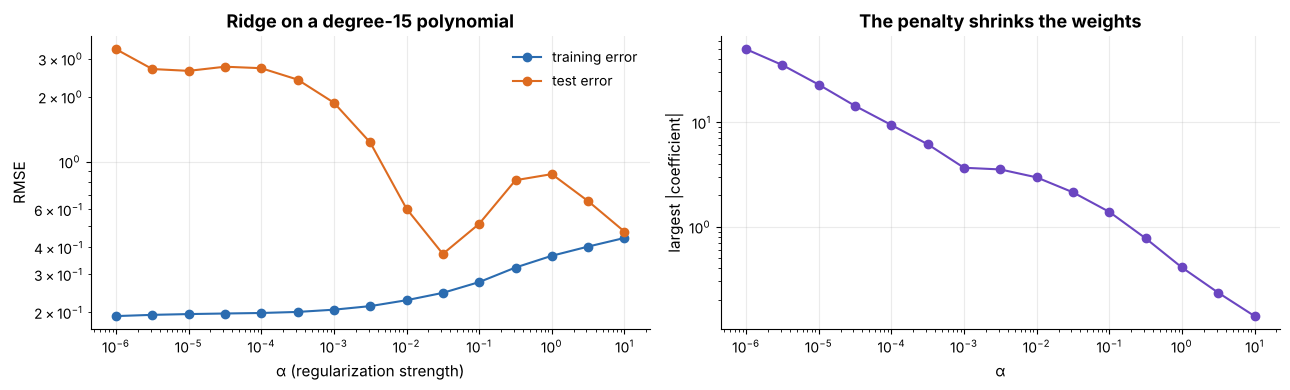

In [7]:
alphas = np.logspace(-6, 1, 15)
tr_e, te_e, max_coef = [], [], []
for a in alphas:
    m = poly_model(15, alpha=a).fit(X_tr, y_tr)
    tr_e.append(rmse(y_tr, m.predict(X_tr))); te_e.append(rmse(y_te, m.predict(X_te)))
    max_coef.append(np.abs(m[-1].coef_).max())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(alphas, tr_e, "o-", color=BLUE, label="training error"); axes[0].plot(alphas, te_e, "o-", color=ORANGE, label="test error")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("α (regularization strength)"); axes[0].set_ylabel("RMSE")
axes[0].set_title("Ridge on a degree-15 polynomial"); axes[0].legend()
axes[1].plot(alphas, max_coef, "o-", color=PURPLE); axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("α"); axes[1].set_ylabel("largest |coefficient|"); axes[1].set_title("The penalty shrinks the weights")
plt.tight_layout(); plt.show()

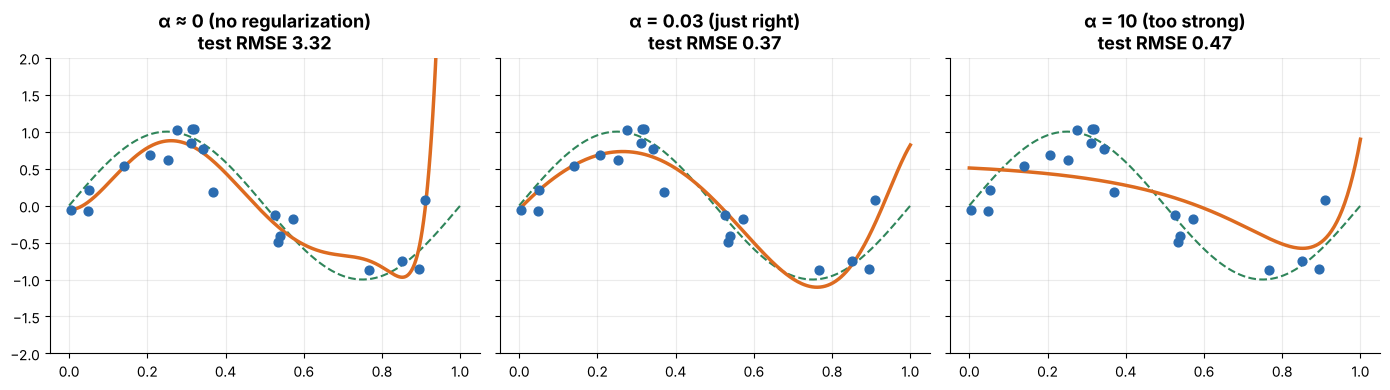

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, a, title in [(axes[0], 1e-6, "α ≈ 0 (no regularization)"), (axes[1], 0.03, "α = 0.03 (just right)"), (axes[2], 10, "α = 10 (too strong)")]:
    m = poly_model(15, alpha=a).fit(X_tr, y_tr)
    ax.scatter(X_tr["x"], y_tr, color=BLUE, s=40, zorder=3)
    ax.plot(xs, np.sin(2 * np.pi * xs), color=GREEN, ls="--", lw=1.5)
    ax.plot(xs, m.predict(pd.DataFrame({"x": xs})), color=ORANGE, lw=2.5)
    ax.set_ylim(-2, 2); ax.set_title(f"{title}\ntest RMSE {rmse(y_te, m.predict(X_te)):.2f}")
plt.tight_layout(); plt.show()

Same degree-15 model; the *only* change is α.

* **α ≈ 0:** the wild overfit from before: huge test error.
* **α moderate:** the curve calms down, hugging the truth: the test error drops dramatically. We tamed a model that was too flexible *without changing its form*.
* **α too big:** the model is forced nearly flat: **underfitting**. Alpha is a dial that slides you along the whole bias–variance spectrum.

### Lasso: regularization that selects features
Because the L1 penalty has "sharp corners" at zero, Lasso sets unimportant coefficients to *exactly* zero. On the diabetes dataset (10 health measurements → disease progression):

In [9]:
diab = load("diabetes.csv")
Xd, yd = diab.drop(columns="disease_progression"), diab["disease_progression"]

rows = []
for a in [0.1, 1, 2, 5]:
    lasso = Lasso(alpha=a).fit(Xd, yd)
    kept = list(Xd.columns[lasso.coef_ != 0])
    rows.append({"alpha": a, "features set to zero": int((lasso.coef_ == 0).sum()), "features kept": ", ".join(kept)})
pd.DataFrame(rows).set_index("alpha")

,features set to zero,features kept
alpha,,
0.1,3,"sex, bmi, bp, s1, s3, s5, s6"
1.0,7,"bmi, bp, s5"
2.0,8,"bmi, s5"
5.0,10,


As α increases, Lasso eliminates features one by one, leaving only the strongest predictors (here: body-mass index `bmi` and the blood-serum measurement `s5` survive longest, with blood pressure `bp` close behind). *Ridge shrinks; Lasso shrinks **and** selects.*

> 📏 **Always standardise features before Ridge/Lasso.** The penalty adds up coefficients; if features have different units, the penalty would punish them unfairly. (Our `poly_model` pipeline does this.)

---
# 📖 Part 5: Cross-validation: a more trustworthy exam

A single train/validation split has a weakness: **your score depends on which rows happened to land in validation.** With a small dataset (like our 20 points!) that's a big lottery.

**K-fold cross-validation** removes the luck:

1. Cut the training data into **k equal folds** (say k = 5).
2. For each fold in turn: **train on the other 4 folds, validate on this one.**
3. You get **k scores**. Report the **mean** (and look at the spread).

Every row is used for validation exactly once and for training k − 1 times.

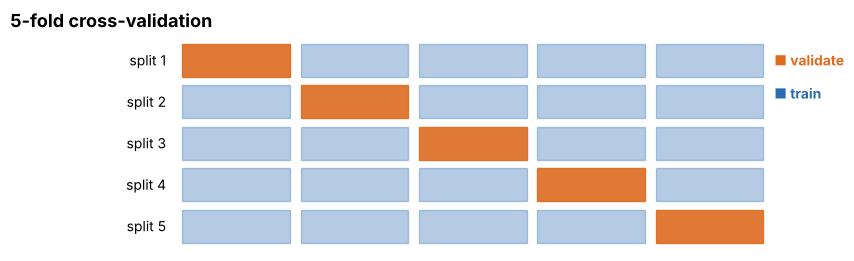

In [10]:
fig, ax = plt.subplots(figsize=(10, 2.8)); ax.axis("off")
for fold in range(5):
    for block in range(5):
        is_val = block == fold
        ax.add_patch(plt.Rectangle((block * 1.1, 4 - fold), 1.0, 0.8, color=ORANGE if is_val else BLUE, alpha=0.9 if is_val else 0.35))
    ax.text(-0.15, 4.4 - fold, f"split {fold+1}", ha="right", va="center", fontsize=10)
ax.set_xlim(-1.6, 5.6); ax.set_ylim(-0.2, 5)
ax.text(5.5, 4.4, "■ validate", color=ORANGE, va="center", fontweight="bold"); ax.text(5.5, 3.6, "■ train", color=BLUE, va="center", fontweight="bold")
ax.set_title("5-fold cross-validation", loc="left"); plt.show()

### 🧑‍🏫 Worked Example 2: 5-fold CV by hand, then by library

Here I do the loop manually so there's no mystery, using the housing data and a linear model:

In [11]:
housing = load("housing.csv")
Xh, yh = housing.drop(columns="price_k"), housing["price_k"]

kf = KFold(n_splits=5, shuffle=True, random_state=0)
fold_scores = []
for fold, (train_idx, val_idx) in enumerate(kf.split(Xh), start=1):
    model = LinearRegression().fit(Xh.iloc[train_idx], yh.iloc[train_idx])     # train on 4 folds
    score = model.score(Xh.iloc[val_idx], yh.iloc[val_idx])                     # R² on the held-out fold
    fold_scores.append(score)
    print(f"fold {fold}: train on {len(train_idx)} rows, validate on {len(val_idx)} rows → R² = {score:.3f}")

print(f"\nmean R² = {np.mean(fold_scores):.3f}  ±  {np.std(fold_scores):.3f}")

# The same thing in ONE line:
print("cross_val_score:", cross_val_score(LinearRegression(), Xh, yh, cv=kf, scoring="r2").round(3))

fold 1: train on 720 rows, validate on 180 rows → R² = 0.972
fold 2: train on 720 rows, validate on 180 rows → R² = 0.967
fold 3: train on 720 rows, validate on 180 rows → R² = 0.968
fold 4: train on 720 rows, validate on 180 rows → R² = 0.960
fold 5: train on 720 rows, validate on 180 rows → R² = 0.961

mean R² = 0.965  ±  0.004
cross_val_score: [0.972 0.967 0.968 0.96  0.961]


`cross_val_score` does exactly that loop. **Report mean ± standard deviation**: the standard deviation tells you how stable the performance is.

**Cross-validation recipes:**

| Variant | Use when |
|---|---|
| `KFold(shuffle=True)` | default for regression |
| `StratifiedKFold` | classification (keeps class ratios in every fold) |
| `TimeSeriesSplit` | time-ordered data: never train on the future! |
| Leave-one-out (k = n) | tiny datasets (slow) |

### Using CV to choose hyperparameters
`GridSearchCV` tries every candidate setting, scores each with cross-validation (on the **training** data only), and refits the best on the whole training set. **The test set stays sealed.**

In [12]:
grid = GridSearchCV(
    poly_model(9, alpha=1.0),                                 # the pipeline: poly → scale → Ridge
    param_grid={"ridge__alpha": np.logspace(-3, 1, 9)},      # step-name__parameter-name
    cv=5, scoring="neg_root_mean_squared_error")
grid.fit(X_tr, y_tr)

print("best alpha found by 5-fold CV:", round(grid.best_params_["ridge__alpha"], 4))
print("CV RMSE of the best alpha     :", round(-grid.best_score_, 3))
print("TEST RMSE (touched once)      :", round(rmse(y_te, grid.predict(X_te)), 3))

best alpha found by 5-fold CV: 0.0032
CV RMSE of the best alpha     : 0.343
TEST RMSE (touched once)      : 0.355


This is the **complete honest recipe** for tuning: *split → cross-validate hyperparameters on the training set → evaluate once on the test set.*

### Learning curves: "would more data help?"
Plot error against **training-set size**. The *shape* tells you what's wrong:

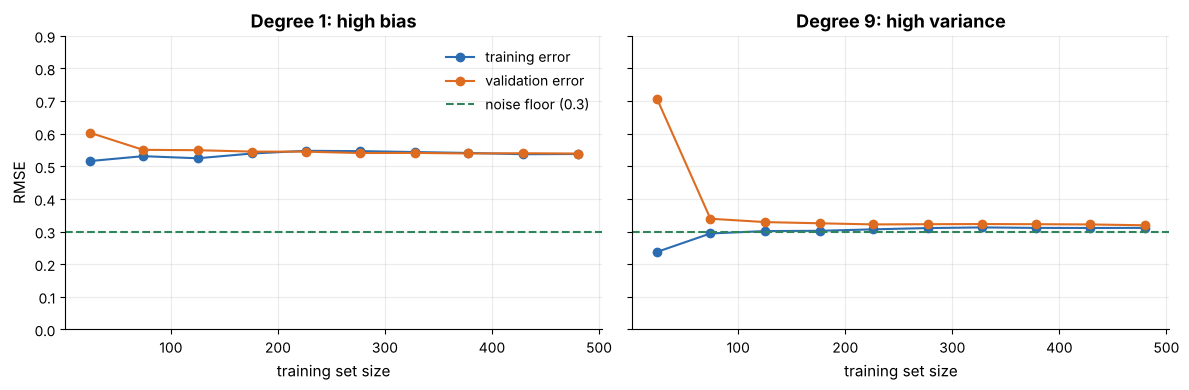

In [13]:
rng = np.random.default_rng(1)
xb = rng.uniform(0, 1, 600)
Xb = pd.DataFrame({"x": xb}); yb = np.sin(2 * np.pi * xb) + rng.normal(0, 0.3, 600)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, deg, title in [(axes[0], 1, "Degree 1: high bias"), (axes[1], 9, "Degree 9: high variance")]:
    sizes, tr, va = learning_curve(poly_model(deg), Xb, yb, train_sizes=np.linspace(0.05, 1, 10), cv=5,
                                   scoring="neg_root_mean_squared_error", random_state=0, shuffle=True)
    ax.plot(sizes, -tr.mean(axis=1), "o-", color=BLUE, label="training error")
    ax.plot(sizes, -va.mean(axis=1), "o-", color=ORANGE, label="validation error")
    ax.axhline(0.3, color=GREEN, ls="--", label="noise floor (0.3)")
    ax.set_xlabel("training set size"); ax.set_title(title); ax.set_ylim(0, 0.9)
axes[0].set_ylabel("RMSE"); axes[0].legend(); plt.tight_layout(); plt.show()

| Curve shape | Diagnosis | What helps |
|---|---|---|
| Both curves **converge to a high error** | **high bias** (underfit) | a more flexible model or better features; **more data won't help** |
| **Big gap** between training and validation error, closing slowly as data grows | **high variance** (overfit) | **more data**, regularization, a simpler model |

---
# 🧩 Your turn: Problems

### 🧩 Problem 5.1: Diagnose the model &nbsp; ⭐

Write `diagnose(train_err, val_err, goal=10)` returning `"underfit"`, `"overfit"` or `"good fit"` using these rules (checked in order):

1. `train_err > goal` → `"underfit"` (can't even fit the training data)
2. else `val_err > 1.5 * train_err` → `"overfit"` (large train/validation gap)
3. otherwise → `"good fit"`

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Use two `if` statements, checked in the order given.

</details>

In [ ]:
def diagnose(train_err, val_err, goal=10):
    return None

print(diagnose(25, 27))

In [ ]:
# ✔ Self-check - run this after you have solved the problem
cases = [((25, 27), "underfit"), ((2, 15), "overfit"), ((8, 9.5), "good fit"),
         ((30, 60), "underfit"), ((5, 7), "good fit"), ((4, 6.5), "overfit")]
for args, expected in cases:
    check(f"train={args[0]}, val={args[1]} → {expected}", lambda: diagnose(*args) == expected)

### 🧩 Problem 5.2: Find the best polynomial degree &nbsp; ⭐⭐

The data is pre-split for you into **train (20), validation (30) and test (30)** points.

1. For every degree from **1 to 12**, fit `poly_model(degree)` on the training set and record the **validation RMSE** in the dictionary `val_errors`.
2. Store the degree with the lowest validation RMSE in `best_degree`.
3. Fit that degree and store its **test RMSE** in `test_error`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`poly_model(d)` is defined at the top of the notebook: it returns an unfitted pipeline.

</details>

<details>
<summary>💡 Hint 2</summary>

`best_degree = min(val_errors, key=val_errors.get)`; then refit `poly_model(best_degree).fit(X_train, y_train)` and score it on `X_test`.

</details>

In [ ]:
curve = load("noisy_curve.csv")
X_c, y_c = curve[["x"]], curve["y"]
X_train, X_rest, y_train, y_rest = train_test_split(X_c, y_c, train_size=20, random_state=3)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=3)

val_errors = {}
best_degree = None
test_error = None
print(best_degree, test_error)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("validation error for degrees 1..12", lambda: sorted(val_errors) == list(range(1, 13)))
check("best_degree has the lowest validation error", lambda: best_degree == min(val_errors, key=val_errors.get))
check("a moderate degree wins (2 ≤ degree ≤ 8)", lambda: 2 <= best_degree <= 8)
check("test RMSE is reasonable (< 0.6)", lambda: test_error < 0.6)

### 🧩 Problem 5.3: Rescue an overfit model with Ridge &nbsp; ⭐⭐

Using the same split as the previous problem (re-created below), compare, on the **validation** set, a **degree-12** polynomial with:

* **no regularization** (`poly_model(12)`) → store its validation RMSE in `plain_val`;
* **Ridge** for each `alpha` in `[1e-4, 1e-3, 1e-2, 0.03, 0.1, 0.3, 1, 3, 10]` (`poly_model(12, alpha=a)`) → store RMSEs in `ridge_val` (`{alpha: rmse}`).

Store the best alpha in `best_alpha`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Same loop pattern as before, but over alphas.

</details>

<details>
<summary>💡 Hint 2</summary>

`best_alpha = min(ridge_val, key=ridge_val.get)`.

</details>

In [ ]:
curve = load("noisy_curve.csv")
X_c, y_c = curve[["x"]], curve["y"]
X_train, X_rest, y_train, y_rest = train_test_split(X_c, y_c, train_size=20, random_state=3)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.5, random_state=3)

alphas = [1e-4, 1e-3, 1e-2, 0.03, 0.1, 0.3, 1, 3, 10]
plain_val = None
ridge_val = {}
best_alpha = None
print(plain_val, best_alpha)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("one RMSE per alpha", lambda: sorted(ridge_val) == sorted(alphas))
check("best_alpha has the lowest validation RMSE", lambda: best_alpha == min(ridge_val, key=ridge_val.get))
check("regularization helps: best Ridge beats the unregularized model", lambda: ridge_val[best_alpha] < plain_val)
check("it helps a lot (at least 20% lower error)", lambda: ridge_val[best_alpha] < 0.8 * plain_val)

### 🧩 Problem 5.4: Which features does Lasso keep? &nbsp; ⭐⭐

On `diabetes.csv` (features: every column except `disease_progression`), fit `Lasso(alpha=1)`.

Store the **number of coefficients that are exactly zero** in `n_zero`, and the **names of the features that survived** in a list `kept_features`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`lasso.coef_ == 0` is a boolean array; `.sum()` counts the `True`s.

</details>

<details>
<summary>💡 Hint 2</summary>

`list(X.columns[lasso.coef_ != 0])` gives the surviving names.

</details>

In [ ]:
diab = load("diabetes.csv")
X = diab.drop(columns="disease_progression")
y = diab["disease_progression"]

n_zero = None
kept_features = None
print(n_zero, kept_features)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_l = Lasso(alpha=1).fit(X, y)
check("count of zeroed coefficients is correct", lambda: n_zero == int((_l.coef_ == 0).sum()))
check("surviving feature names are correct", lambda: sorted(kept_features) == sorted(X.columns[_l.coef_ != 0]))
check("'bmi' survived (it is the strongest predictor)", lambda: "bmi" in kept_features)

### 🧩 Problem 5.5: Cross-validate three models &nbsp; ⭐⭐

Compare these three models on `housing.csv` (target `price_k`) using **5-fold cross-validation** with `KFold(n_splits=5, shuffle=True, random_state=0)` and R² scoring:

* `"LinearRegression"`: `LinearRegression()`
* `"Ridge"`: `make_pipeline(StandardScaler(), Ridge(alpha=10))`
* `"KNN"`: `make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=10))`

Store the **mean R²** of each in `cv_means` (keyed by the names above) and the name of the winner in `best_name`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`cross_val_score(model, X, y, cv=kf, scoring="r2")` returns 5 scores; take `.mean()`.

</details>

<details>
<summary>💡 Hint 2</summary>

Put the models in a dictionary and loop over it. `best_name = max(cv_means, key=cv_means.get)`.

</details>

In [ ]:
housing = load("housing.csv")
X, y = housing.drop(columns="price_k"), housing["price_k"]
kf = KFold(n_splits=5, shuffle=True, random_state=0)

cv_means = {}
best_name = None
print(cv_means, best_name)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("three models evaluated", lambda: sorted(cv_means) == ["KNN", "LinearRegression", "Ridge"])
check("winner is the model with the highest mean R²", lambda: best_name == max(cv_means, key=cv_means.get))
check("KNN is clearly the weakest here (R² < 0.9)", lambda: cv_means["KNN"] < 0.9)
check("linear models score above 0.95", lambda: cv_means["LinearRegression"] > 0.95 and cv_means["Ridge"] > 0.95)

### 🧩 Problem 5.6: Cross-validation from scratch &nbsp; ⭐⭐⭐

Implement `my_cross_val(model, X, y, k=5)` **without** `cross_val_score` or `KFold`.

* Split the row positions `0..n−1` into `k` consecutive folds with `np.array_split`.
* For each fold: `clone(model)`, fit on the other folds, compute `score` (R²) on the held-out fold.
* Return the **mean** of the k scores.

*(`X` is a DataFrame, `y` a Series; use `.iloc` with index arrays.)*

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`folds = np.array_split(np.arange(len(X)), k)` gives the validation positions for each fold.

</details>

<details>
<summary>💡 Hint 2</summary>

The training positions for fold `i` are all the other folds concatenated: `np.concatenate([f for j, f in enumerate(folds) if j != i])`.

</details>

<details>
<summary>💡 Hint 3</summary>

`clone(model).fit(X.iloc[train_pos], y.iloc[train_pos]).score(X.iloc[val_pos], y.iloc[val_pos])` is one fold's R².

</details>

In [ ]:
def my_cross_val(model, X, y, k=5):
    return None

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_h = load("housing.csv")
_X, _y = _h.drop(columns="price_k"), _h["price_k"]
_mine = my_cross_val(LinearRegression(), _X, _y, k=5)
_ref = cross_val_score(LinearRegression(), _X, _y, cv=KFold(n_splits=5), scoring="r2").mean()
check("matches sklearn's cross_val_score (no-shuffle KFold)", lambda: abs(_mine - _ref) < 1e-9)
check("works with k=10 too", lambda: 0.9 < my_cross_val(Ridge(alpha=1), _X, _y, k=10) < 1.0)

---
## 🎟️ Exit ticket

**Q1.** A model has training RMSE 1.2 and validation RMSE 9.8. Diagnose it and suggest two cures.
**Q2.** A model has training RMSE 20 and validation RMSE 21 (target noise ≈ 5). Diagnose it and suggest a cure.
**Q3.** Which part of the bias–variance decomposition can *never* be reduced by a better model?
**Q4.** What does increasing α in Ridge do? What if it's too large?
**Q5.** Why is 5-fold CV a more reliable estimate than a single 80/20 split?

<details><summary>👀 Answers</summary>

**A1.** Overfitting (high variance). Cures: more training data, a simpler model, regularization / stronger α, fewer features.
**A2.** Underfitting (high bias): even training error is far above the noise level. Cure: a more flexible model, better/extra features, weaker regularization.
**A3.** The irreducible noise σ².
**A4.** It shrinks coefficients, giving a smoother, simpler model (lower variance, higher bias). Too large → underfitting.
**A5.** Every observation is used for validation exactly once and the result is averaged, so it doesn't depend on one lucky or unlucky split; the fold-to-fold spread also shows how stable the estimate is.

</details>

---
## 📌 Recap: Lesson 5 on one page

* **Generalization** = good performance on *unseen* data. That's the only thing that matters.
* **Underfit** = high training error (too simple, high bias). **Overfit** = low training error but much higher validation error (too flexible, high variance).
* **Bias–variance:** expected error = bias² + variance + noise. Complexity ↑ → bias ↓, variance ↑. Aim for the *sum's* minimum.
* **Regularization:** loss + α·penalty. **Ridge** (L2) shrinks weights; **Lasso** (L1) shrinks *and* zeroes some. Standardise first; tune α.
* **Cross-validation:** k folds → k scores → mean ± std. Use `GridSearchCV` to tune on the training set; test set only at the end.
* **Learning curves** tell you whether to add data (variance) or add capacity (bias).

**Next up →** `06_regression_metrics.ipynb`: we've been using RMSE casually: now we study how to measure regression models properly.